In [1]:
]activate ../../../../

  Activating project at `~/UCLOneDrive/SpatialStructureInMicrobialCommunities/SSMCCode`

In [2]:
using Revise
includet("./base.jl")

In [3]:
includet("../../../../scripts/figures_util.jl")

In [4]:
using GLMakie
using CairoMakie
CairoMakie.activate!()

# Load analyzed dataframe

In [5]:
df = load("./analyzed_df.jld2", "df");

In [6]:
full_md = df.settings[1]
md = full_md.setup_metadata;

# Checking final state peak finding in total biomass

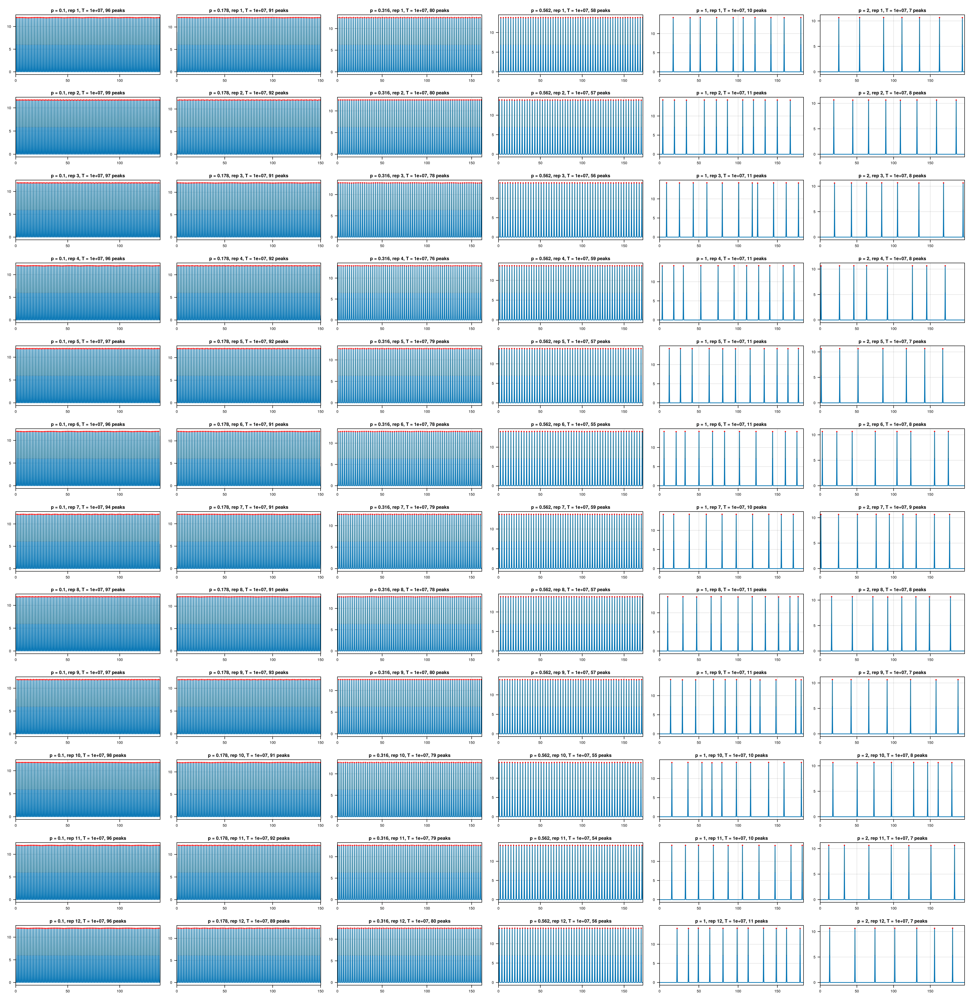

In [17]:
relheight = 0.5 # what df.peaks was found with
fig = Figure(size=(350 * maximum(df.p_i), 180 * maximum(df.rep)))
for r in eachrow(df)
    dx = r.L / r.sN
    xs = ((1:r.sN) .- 0.5) .* dx
    ex(e) = (e - 0.5) * dx
    N = r.saved_us[end][1, :]
    p = r.peaks[end]

    ax = Axis(fig[r.rep, r.p_i];
        title=@sprintf("p = %.3g, rep %d, T = %.3g, %d peaks", r.p, r.rep, r.final_T, length(p.indices)),
        titlesize=10, xticklabelsize=8, yticklabelsize=8)
    lines!(ax, xs, N)
    if !isempty(p.indices)
        # width lines and the shaded area above them, split where a peak wraps
        segs = Pair{Point2f,Point2f}[]
        lo, hi = fill(NaN, r.sN), fill(NaN, r.sN)
        for (k, (l, rr)) in enumerate(p.edges)
            y = p.heights[k] - relheight * p.proms[k]
            if rr <= r.sN + 0.5
                push!(segs, Point2f(ex(l), y) => Point2f(ex(rr), y))
            else
                push!(segs, Point2f(ex(l), y) => Point2f(r.L, y), Point2f(0, y) => Point2f(ex(rr - r.sN), y))
            end
            for j in mod1.(ceil(Int, l):floor(Int, rr), r.sN)
                lo[j], hi[j] = y, N[j]
            end
        end
        band!(ax, xs, lo, hi; color=(:orange, 0.4))
        linesegments!(ax, segs; color=:black, linewidth=0.5)
        scatter!(ax, xs[p.indices], p.heights; color=:red, markersize=4)
    end
    xlims!(ax, 0, r.L)
end
Makie.save("peaks_at_final_T.pdf", fig)
fig

# Peaks and width in final state

In [23]:
fpp_kwargs = (; relheight=0.99)
df.peaks_N = [find_peaks_periodic(u[1, :]; fpp_kwargs...) for u in df.final_state]
df.peaks_I = [find_peaks_periodic(-u[2, :]; fpp_kwargs...) for u in df.final_state]
df.peaks_R = [find_peaks_periodic(u[3, :]; fpp_kwargs...) for u in df.final_state]

# mean peak width in x units (find_peaks_periodic gives gridpoints)
dx = df.L ./ df.sN
df.width_N = [mean(pk.widths) for pk in df.peaks_N] .* dx
df.width_I = [mean(pk.widths) for pk in df.peaks_I] .* dx
df.width_R = [mean(pk.widths) for pk in df.peaks_R] .* dx

df[:, [:pde_df_row, :p, :rep, :L, :width_N, :width_I, :width_R]];

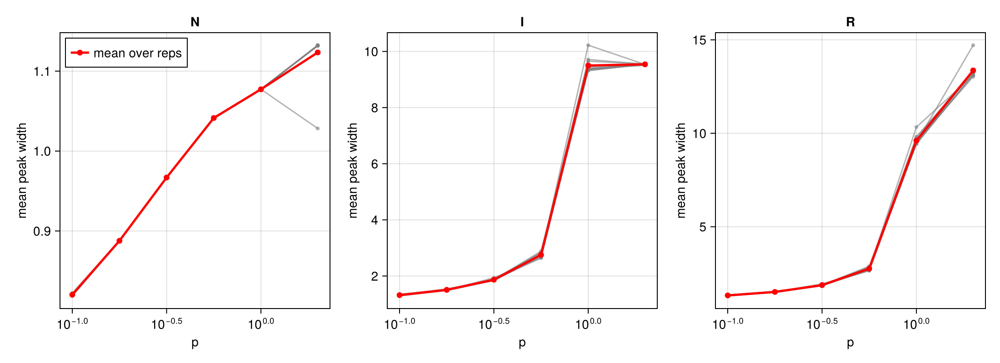

In [24]:
ps = sort(unique(df.p))
fig = Figure(size=(1100, 400))
for (j, (col, name)) in enumerate([(:width_N, "N"), (:width_I, "I"), (:width_R, "R")])
    ax = Axis(fig[1, j]; xscale=log10, xlabel="p", ylabel="mean peak width", title=name)
    for rep in unique(df.rep)
        sdf = sort(df[df.rep .== rep, :], :p)
        scatterlines!(ax, sdf.p, sdf[!, col]; color=(:gray, 0.6), markersize=6)
    end
    means = [mean(df[df.p .== p, col]) for p in ps]
    scatterlines!(ax, ps, means; color=:red, linewidth=2.5, label="mean over reps")
    j == 1 && axislegend(ax; position=:lt)
end
fig

# Playing around

In [17]:
r = df[1+12*5,:];
N = r.final_state[1,:]
I = r.final_state[2,:]
R = r.final_state[3,:];

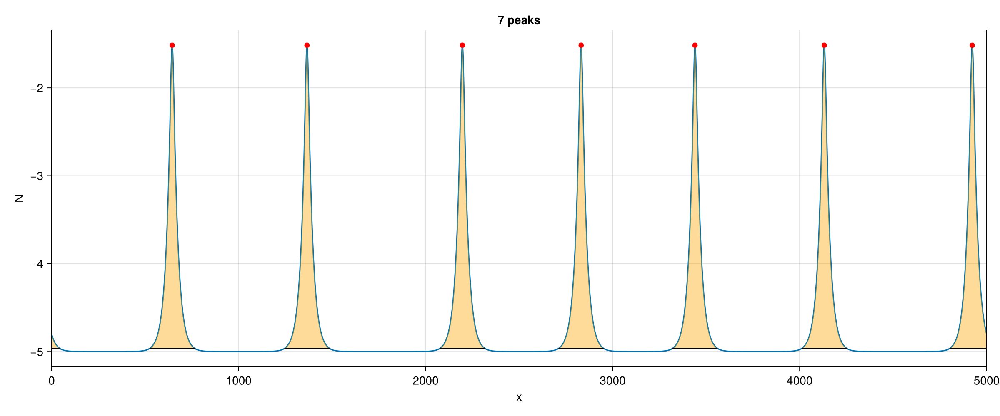

In [22]:
plot_peaks(-I; relheight=0.99)

# Util/testing functions

In [16]:
function plot_peaks(N, L=length(N); relheight=0.5, kwargs...)
    sN = length(N)
    dx = L / sN
    xs = ((1:sN) .- 0.5) .* dx
    ex(e) = (e - 0.5) * dx
    p = find_peaks_periodic(N; relheight, kwargs...)

    fig = Figure(size=(1200, 500))
    ax = Axis(fig[1, 1]; xlabel="x", ylabel="N", title="$(length(p.indices)) peaks")
    lines!(ax, xs, N)
    if !isempty(p.indices)
        # width lines and the shaded area above them, split where a peak wraps
        segs = Pair{Point2f,Point2f}[]
        lo, hi = fill(NaN, sN), fill(NaN, sN)
        for (k, (l, rr)) in enumerate(p.edges)
            y = p.heights[k] - relheight * p.proms[k]
            if rr <= sN + 0.5
                push!(segs, Point2f(ex(l), y) => Point2f(ex(rr), y))
            else
                push!(segs, Point2f(ex(l), y) => Point2f(L, y), Point2f(0, y) => Point2f(ex(rr - sN), y))
            end
            for j in mod1.(ceil(Int, l):floor(Int, rr), sN)
                lo[j], hi[j] = y, N[j]
            end
        end
        band!(ax, xs, lo, hi; color=(:orange, 0.4))
        linesegments!(ax, segs; color=:black)
        scatter!(ax, xs[p.indices], p.heights; color=:red)
    end
    xlims!(ax, 0, L)
    fig
end

plot_peaks (generic function with 2 methods)